In [1]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import matplotlib



os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
import Treat_acoustic_func as Treat_acoustic_func
importlib.reload(Treat_acoustic_func)
from Treat_acoustic_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
import Treat_acoustic_plotting as Treat_acoustic_plotting
importlib.reload(Treat_acoustic_plotting)
from Treat_acoustic_plotting import *




fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [2]:
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\Acoustic\Silice thick\Q factor - radiative\2025-11'

Shapes = ['cylinder', 'round corner',  'round']

Colors = {}

Colors['cylinder'], Colors['round corner'], Colors['round'] = ['black', 'blue', 'green']
Spectra_data = {}

for shape in Shapes :

    dir_spectra= dir_root + r'\\' + shape
    Fname_list = ['size_sweep_AR_1.5_6', 'size_sweep_AR_6_8']
    n_parameters=2
    Spectra_data[shape]= get_raw_size_sweep_data_Nathan(dir_spectra, Fname_list, verbose=True)

Total size of raw data : 6370
----------- Find spectra size -----------
idx start : 0
value start : (12.801042505478996+9.145062600394702j)
end index : 69
value end : (41.21188115933463+0.13828293223780402j)
----------- Find spectra size -----------
idx start : 70
value start : (12.801169429443494+9.145095801526889j)
end index : 139
value end : (40.81092129817771+11.87035773440035j)
----------- Find spectra size -----------
idx start : 140
value start : (12.801293971474184+9.145130612417706j)
end index : 209
value end : (40.87320506386742+11.883791822700204j)
----------- Find spectra size -----------
idx start : 210
value start : (12.801416072459535+9.145167482168024j)
end index : 279
value end : (40.93508147767701+11.89833323874511j)
----------- Find spectra size -----------
idx start : 280
value start : (12.66660530018665+1.5542740357339249j)
end index : 349
value end : (40.99717613715677+11.913531613227848j)
----------- Find spectra size -----------
idx start : 350
value start : (12

In [3]:
#plot_all_raw_spectra_interactive(Spectra_cylinder)

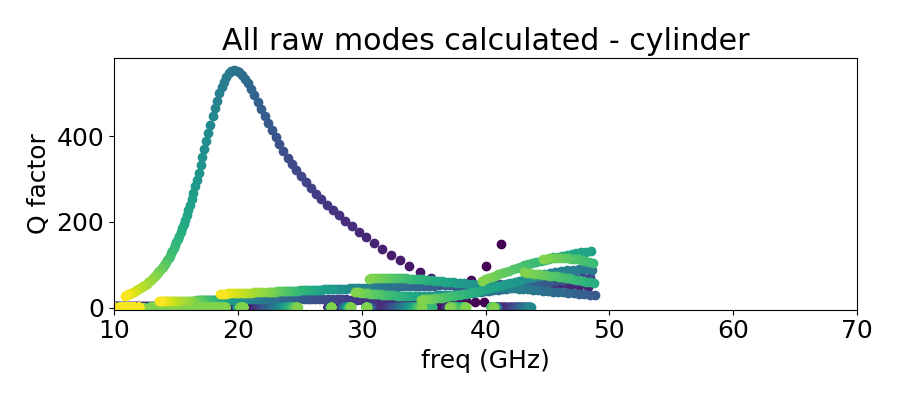

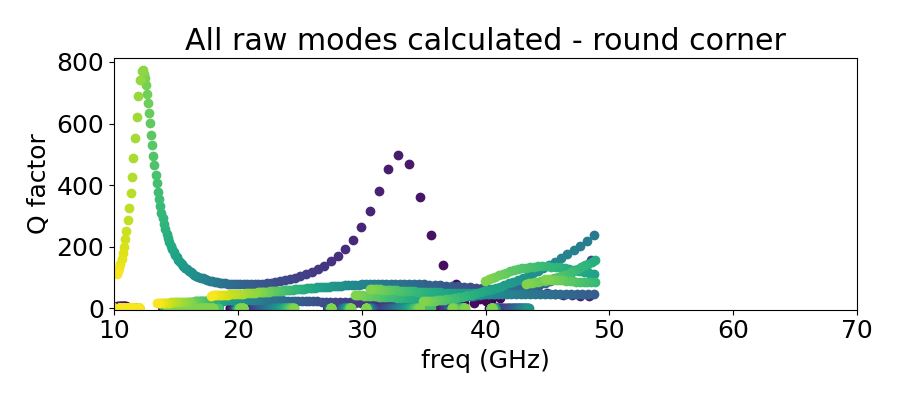

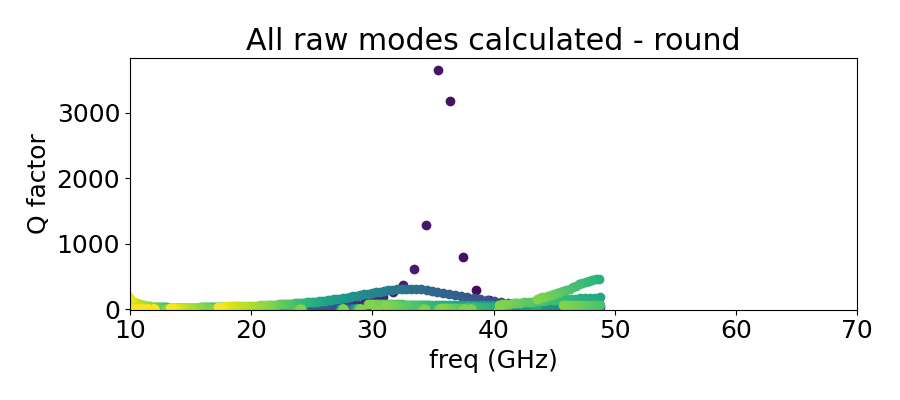

In [4]:
bottom = -5
top=110
xlim = (10, 70)

for key in Spectra_data :
    spectra = Spectra_data[key]

    fig, ax = plt.subplots(figsize = (9,4))

    plot_all_raw_spectra(spectra, ax, plotted_key = 'Q')

    ax.set_xlabel('freq (GHz)')
    ax.set_ylabel('Q factor')
    ax.set_ylim(bottom=bottom )
    #ax.set_ylim( top=top)
    ax.set_xlim(xlim)
    ax.set_title('All raw modes calculated - ' + key)
    #plt.legend(fontsize=10)
    plt.tight_layout()



In [5]:
for key in Spectra_data :
    spectra = Spectra_data[key]
    get_modes_with_Q_selection(spectra, Q_th=3)

## def freq limit functions to extract Q factor

In [6]:
## For cylinder

def f1_low(ar) :
    return(30/(ar**0.55))

def f1_high(ar) :
    return(53/(ar**0.52))


## For round corner

def f2_low(ar) :
    return(36/(ar))

def f2_high(ar) :
    return(60/(ar**0.7))


## For round
def f3_low(ar) :
    return(36/(ar))

def f3_high(ar) :
    return(60/(ar**0.7))


Boundary_func = {}
Boundary_func['cylinder'] = (lambda x : x*0, f1_high)
Boundary_func['round corner'] = (f2_low, f2_high)
Boundary_func['round'] = (f3_low, f3_high)


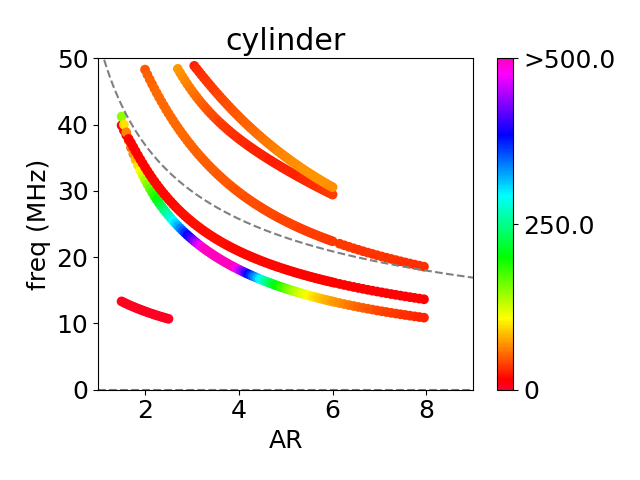

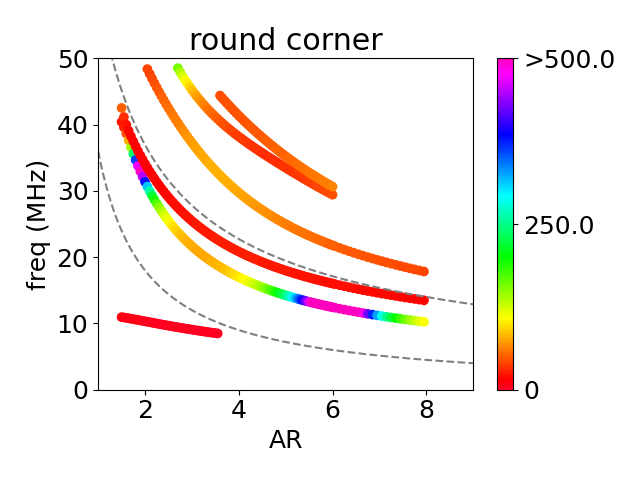

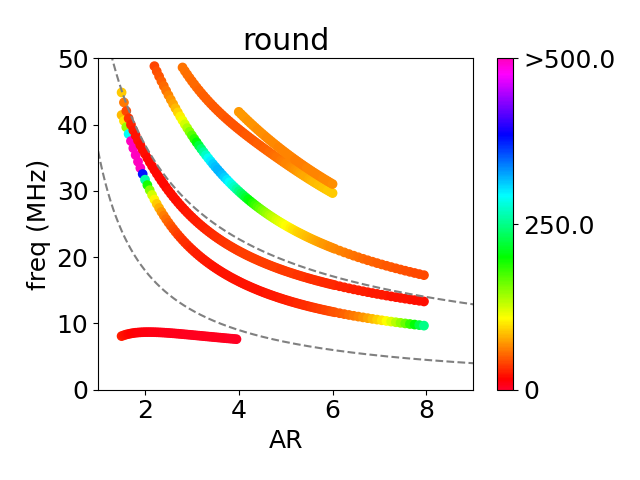

In [7]:
Q_max = 500
xlim = (1, 9)
ylim = (0, 50)
AR_array = np.linspace(xlim[0], xlim[1], 1000)


for key in Spectra_data :
    spectra = Spectra_data[key]
   


    fig, ax = plt.subplots()

    plot_all_acoustic_modes(spectra, ax, Q_max = Q_max, n_modes = 5)

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    plt.xlabel('AR')
    plt.ylabel('freq (MHz)')
    plt.title(key)
    plt.tight_layout()

    dir_to_save = dir_root + r'\\' + key + r'\Figures'
    if not(os.path.exists(dir_to_save)) :
        os.mkdir(dir_to_save)
    os.chdir(dir_to_save)
    plt.savefig('freq(AR).pdf')
    plt.savefig('freq(AR).png')



    ax.plot(AR_array, Boundary_func[key][0](AR_array), linestyle='--', color='grey')
    ax.plot(AR_array, Boundary_func[key][1](AR_array), linestyle='--', color='grey')



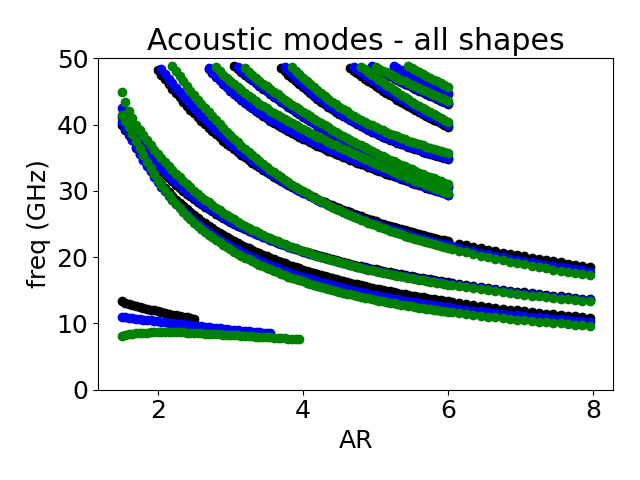

In [8]:
fig, ax = plt.subplots()

for key in Spectra_data :
    spectra = Spectra_data[key]
    


    for kkey in spectra :
        single_ND_modes = spectra[kkey]
        #print(np.sum(spectra['projection']))
        #print(spectra['eigen_freq'][np.argmax(spectra['projection'])])
        ax.scatter(single_ND_modes['AR']*np.ones(np.size(single_ND_modes['modes']['f'])), single_ND_modes['modes']['f'], color=Colors[key])


plt.title('Acoustic modes - all shapes')
plt.ylim(ylim)
plt.xlabel('AR')
plt.ylabel('freq (GHz)')
plt.tight_layout()

dir_to_save = dir_root  + r'\Figures'
if not(os.path.exists(dir_to_save)) :
    os.mkdir(dir_to_save)
os.chdir(dir_to_save)
plt.savefig('freq(AR) - all shapes.pdf')
plt.savefig('freq(AR) - all shapes.png')

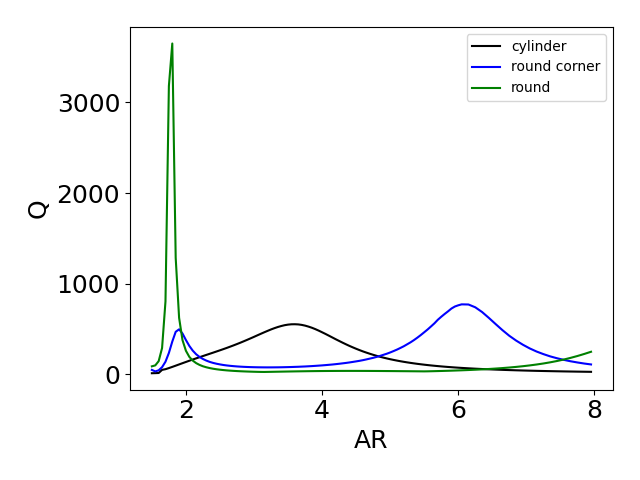

In [9]:
AR_min = 1.5
AR_max = 13

fig, ax = plt.subplots()



for key in Spectra_data :
    spectra = Spectra_data[key]
    AR, Q = get_max_Q(spectra, freq_low_func=Boundary_func[key][0], freq_high_func=Boundary_func[key][1],AR_min=AR_min, AR_max=AR_max)
    ax.plot(AR, Q, color=Colors[key], label = key)




plt.xlabel('AR')
plt.ylabel('Q')
plt.legend(fontsize=10)
plt.tight_layout()

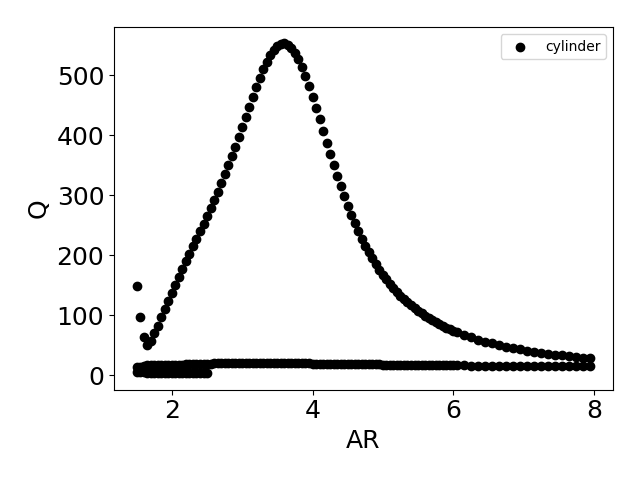

In [12]:
AR_all_shapes = {}
Q_all_shapes = {}
Freq_all_shapes = {}

fig, ax = plt.subplots()

# for key in Spectra_data :
for key in ['cylinder'] :
    spectra = Spectra_data[key]
    AR_all_shapes[key],  Freq_all_shapes[key], Q_all_shapes[key] = get_Q_specific_bands(spectra, freq_low_func=Boundary_func[key][0], freq_high_func=Boundary_func[key][1], AR_min=AR_min, AR_max=AR_max)
    ax.scatter(AR_all_shapes[key],  Q_all_shapes[key], color=Colors[key], label = key)

plt.xlabel('AR')
plt.ylabel('Q')
plt.legend(fontsize=10)
plt.tight_layout()


dir_to_save = dir_root  + r'\Figures'
if not(os.path.exists(dir_to_save)) :
    os.mkdir(dir_to_save)
os.chdir(dir_to_save)
plt.savefig('Q(AR) - all shapes.pdf')
plt.savefig('Q(AR) - all shapes.png')

## Save data

In [11]:
if 0 :
        
    for key in Spectra_data :
        spectra = Spectra_data[key]
        dir_to_save = dir_root + r'\\' + key + r'\Treated data'
        save_Q_with_AR_to_csv(dir_to_save, 'Selected acoustic modes', Q_all_shapes[key], AR_all_shapes[key], Freq_all_shapes[key])
        save_freq_with_AR_to_csv(dir_to_save, 'Q and freq', spectra)
